# Stage 1: raw pixels

Softmax classifier (multinomial logistic regression) on the 784 raw pixel values. Sweeps C on the group-aware split and on a random split, evaluates the chosen model once on the official test set, and draws the weight images and the confusion analysis used in the Stage 1 report.

## Setup

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().resolve()
while not (ROOT / "src" / "signlang").is_dir():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))
sys.path.insert(0, str(ROOT))

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from signlang.seed import set_seed
from signlang.data import LETTERS, load_train, load_test
from signlang.split import load_split
from signlang.softmax import fit_softmax, sweep_C
from signlang.metrics import accuracy, macro_f1, confusion, top_confused_pairs
from signlang.plotting import curve, weight_images, confusion_heatmap, image_grid, savefig
from tools.build_tables import df_to_tex

set_seed(42)
FIG = ROOT / "reports" / "figures" / "stage1"
TAB = ROOT / "reports" / "tables"
MODELS = ROOT / "models"
CS = [0.001, 0.01, 0.1, 1, 10, 100]
WEIGHT_LETTERS = ["A", "B", "C", "L", "Y"]

## Data and splits

In [2]:
X, y = load_train()
Xte, yte = load_test()
s = load_split()
Xtr, ytr = X[s["train_idx"]], y[s["train_idx"]]
Xva, yva = X[s["val_idx"]], y[s["val_idx"]]
Xrtr, yrtr = X[s["rand_train_idx"]], y[s["rand_train_idx"]]
Xrva, yrva = X[s["rand_val_idx"]], y[s["rand_val_idx"]]
print(f"group split:  train {len(ytr)}, val {len(yva)}")
print(f"random split: train {len(yrtr)}, val {len(yrva)}")
print(f"test set:     {len(yte)}")

group split:  train 22003, val 5452
random split: train 21964, val 5491
test set:     7172


## Sweep over C: group split

In [3]:
sweep_group = sweep_C(Xtr, ytr, Xva, yva, CS)
sweep_group

,C,val_acc,val_f1,seconds,n_iter,converged
0,0.001,0.425715,0.414470,7.130902,134,True
1,0.010,0.585657,0.586616,19.670148,252,True
2,0.100,0.658107,0.661960,42.802406,429,True
3,1.000,0.655539,0.656420,64.042800,308,True
4,10.000,0.656090,0.656317,21.602924,213,True
5,100.000,0.623074,0.625634,16.461947,153,True


## Sweep over C: random split

In [4]:
sweep_random = sweep_C(Xrtr, yrtr, Xrva, yrva, CS)
sweep_random

,C,val_acc,val_f1,seconds,n_iter,converged
0,0.001,0.617920,0.611593,18.364109,102,True
1,0.010,0.832271,0.834360,14.377284,237,True
2,0.100,0.983063,0.983435,24.488763,441,True
3,1.000,0.999454,0.999460,16.995453,309,True
4,10.000,0.999636,0.999648,15.942265,234,True
5,100.000,0.997632,0.997648,14.358121,163,True


## Validation accuracy against C

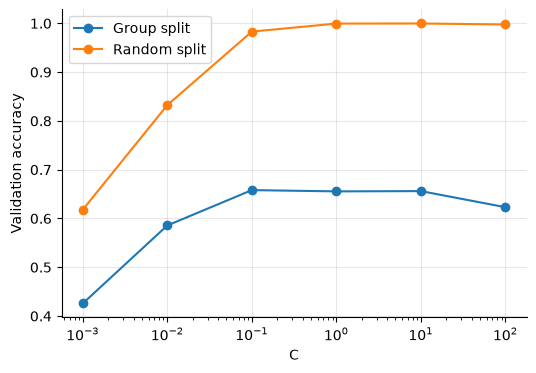

,C,Val acc (group split),Val acc (random split),Fit time (s),Converged
0,0.001,0.425715,0.617920,7.1,yes
1,0.01,0.585657,0.832271,19.7,yes
2,0.1,0.658107,0.983063,42.8,yes
3,1,0.655539,0.999454,64.0,yes
4,10,0.656090,0.999636,21.6,yes
5,100,0.623074,0.997632,16.5,yes


In [5]:
fig = curve(CS, [sweep_group["val_acc"], sweep_random["val_acc"]],
            ["Group split", "Random split"], xlabel="C", ylabel="Validation accuracy",
            logx=True)
savefig(fig, FIG / "c_sweep.pdf")
plt.show()

sweep_table = pd.DataFrame({
    "C": [f"{c:g}" for c in CS],
    "Val acc (group split)": sweep_group["val_acc"],
    "Val acc (random split)": sweep_random["val_acc"],
    "Fit time (s)": [f"{t:.1f}" for t in sweep_group["seconds"]],
    "Converged": np.where(sweep_group["converged"], "yes", "no"),
})
df_to_tex(sweep_table, TAB / "s1_C_sweep.tex")
sweep_table

## Chosen C

In [6]:
best = sweep_group["val_acc"].max()
C_STAR = float(sweep_group.loc[sweep_group["val_acc"] == best, "C"].min())
print("C* =", C_STAR)

C* = 0.1


## Refit at the chosen C

In [7]:
model, info = fit_softmax(Xtr, ytr, C_STAR)
print(info)
MODELS.mkdir(exist_ok=True)
joblib.dump(model, MODELS / "stage1_softmax.joblib");

{'seconds': 36.228607000084594, 'n_iter': 429, 'converged': True}


## Test set (evaluated once)

In [8]:
pred_va = model.predict(Xva)
pred_te = model.predict(Xte)
rand_at_cstar = sweep_random.loc[sweep_random["C"] == C_STAR].iloc[0]
test_table = pd.DataFrame({
    "Evaluated on": ["Validation (group split)", "Validation (random split)", "Test"],
    "Accuracy": [accuracy(yva, pred_va), rand_at_cstar["val_acc"], accuracy(yte, pred_te)],
    "Macro-F1": [macro_f1(yva, pred_va), rand_at_cstar["val_f1"], macro_f1(yte, pred_te)],
})
df_to_tex(test_table, TAB / "s1_test.tex")
test_table

,Evaluated on,Accuracy,Macro-F1
0,Validation (group split),0.658107,0.661960
1,Validation (random split),0.983063,0.983435
2,Test,0.659509,0.645186


## Weight images

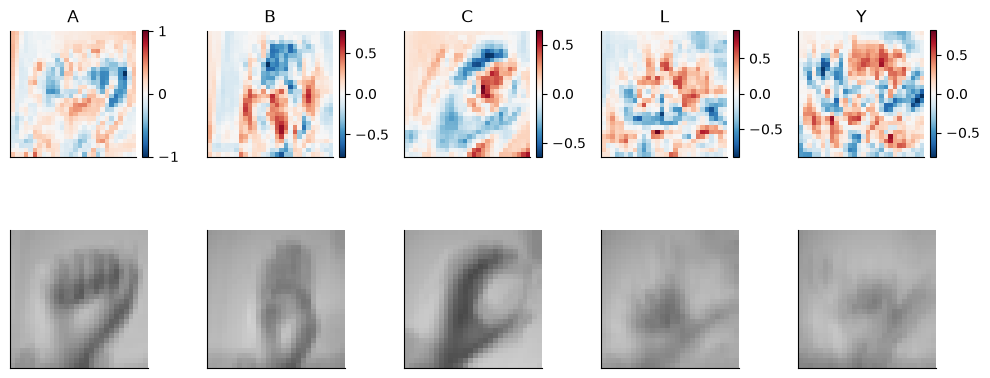

In [9]:
idx = [LETTERS.index(letter) for letter in WEIGHT_LETTERS]
means = [Xtr[ytr == c].mean(axis=0) for c in idx]
fig = weight_images(model.coef_[idx], WEIGHT_LETTERS, mean_images=means)
savefig(fig, FIG / "weights.pdf")
plt.show()

## Confusion matrix (test set)

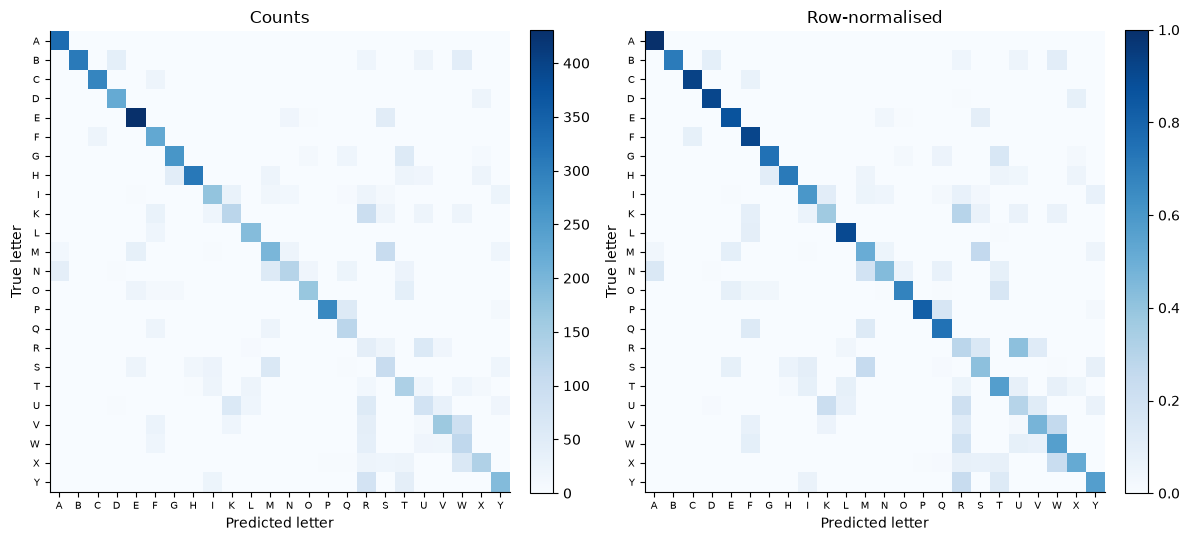

In [10]:
cm = confusion(yte, pred_te)
fig, axes = plt.subplots(1, 2, figsize=(12, 5.5))
confusion_heatmap(cm, ax=axes[0], title="Counts")
confusion_heatmap(cm, normalize=True, ax=axes[1], title="Row-normalised")
fig.tight_layout()
savefig(fig, FIG / "confusion.pdf")
plt.show()

## Most confused pairs

In [11]:
pairs = top_confused_pairs(cm, 5)
pairs_table = pd.DataFrame(pairs, columns=["True", "Predicted", "Count", "Reverse count"])
pairs_table["Total"] = pairs_table["Count"] + pairs_table["Reverse count"]
df_to_tex(pairs_table, TAB / "s1_confused_pairs.tex")
pairs_table

,True,Predicted,Count,Reverse count,Total
0,M,S,103,61,164
1,R,U,60,55,115
2,V,W,89,16,105
3,K,R,97,0,97
4,U,K,60,21,81


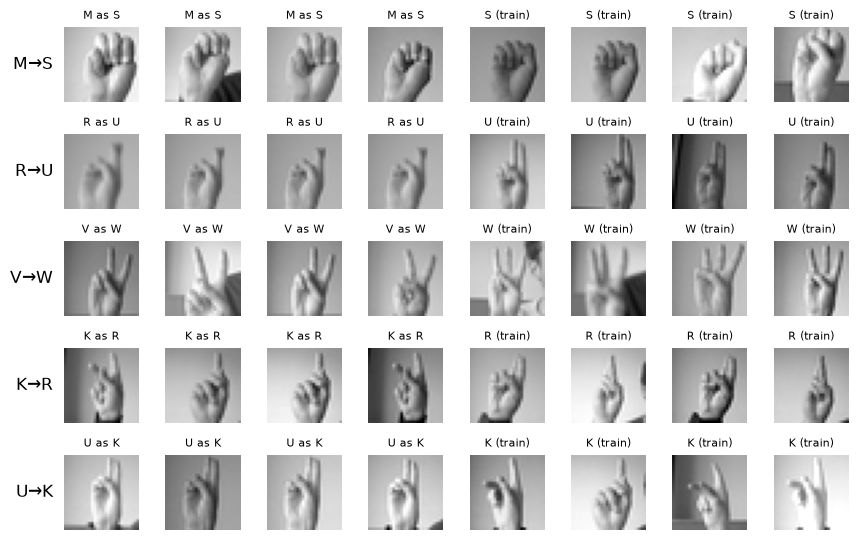

In [12]:
rng = np.random.default_rng(42)
blank = np.full(784, np.nan)
images, titles = [], []
for a, b, *_ in pairs:
    ia, ib = LETTERS.index(a), LETTERS.index(b)
    wrong = np.flatnonzero((yte == ia) & (pred_te == ib))
    wrong = rng.choice(wrong, size=min(4, len(wrong)), replace=False)
    train_b = rng.choice(np.flatnonzero(ytr == ib), size=4, replace=False)
    images += [Xte[i] for i in wrong] + [blank] * (4 - len(wrong))
    titles += [f"{a} as {b}"] * len(wrong) + [""] * (4 - len(wrong))
    images += [Xtr[i] for i in train_b]
    titles += [f"{b} (train)"] * 4
fig = image_grid(images, titles=titles, ncols=8, panel_size=1.1,
                 row_labels=[f"{a}\u2192{b}" for a, b, *_ in pairs])
savefig(fig, FIG / "confused_pairs.pdf")
plt.show()

## ASL reference picture

In [13]:
print(ROOT / "docs" / "Dataset" / "american_sign_language.PNG")

C:\Users\USER\Desktop\Project in Machine Learning\Reading-Sign-Language\docs\Dataset\american_sign_language.PNG
